# 🏆 Datathon 2026 - Career Success Score Prediction

**Amaç:** Öğrencilerin akademik, teknik, proje, portfolyo, mülakat ve kariyer hazırlık süreçlerine ait verilerden `career_success_score` değerini tahmin etmek.

**Metrik:** MSE (Mean Squared Error)

**Yaklaşım:**
1. Keşifçi Veri Analizi (EDA)
2. Veri Ön İşleme & Feature Engineering
3. NLP - Mentor Feedback Text Analizi
4. Model Eğitimi (XGBoost, LightGBM, CatBoost)
5. Ensemble & Stacking
6. Submission Dosyası Oluşturma

## 1. Kütüphaneler ve Ayarlar

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Sklearn
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from sklearn.metrics import mean_squared_error
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import Ridge

# Gradient Boosting modelleri
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

# Görselleştirme ayarları
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)

SEED = 42
np.random.seed(SEED)

print('✅ Kütüphaneler başarıyla yüklendi.')

✅ Kütüphaneler başarıyla yüklendi.


## 2. Veri Yükleme

In [2]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test_x.csv')
sample_sub = pd.read_csv('sample_submission.csv')

print(f'Train shape: {train.shape}')
print(f'Test shape:  {test.shape}')
print(f'Sample submission shape: {sample_sub.shape}')
print(f'\nTrain kolonları:\n{list(train.columns)}')

Train shape: (10000, 47)
Test shape:  (10000, 46)
Sample submission shape: (2, 2)

Train kolonları:
['student_id', 'application_year', 'age', 'graduation_year', 'department', 'university_tier', 'cgpa', 'english_exam_score', 'attendance_rate', 'failed_courses_count', 'target_role', 'coding_score', 'problem_solving_score', 'data_structures_score', 'sql_score', 'machine_learning_score', 'backend_score', 'frontend_score', 'cloud_score', 'devops_score', 'project_quality_score', 'real_client_project_count', 'internship_count', 'internship_duration_months', 'freelance_project_count', 'hackathon_count', 'hackathon_awards', 'portfolio_score', 'github_repo_count', 'github_avg_stars', 'open_source_contribution_count', 'linkedin_profile_score', 'cv_quality_score', 'technical_interview_score', 'hr_interview_score', 'communication_score', 'teamwork_score', 'leadership_score', 'presentation_score', 'certification_count', 'bootcamp_count', 'applications_sent', 'interviews_attended', 'hobby', 'preferre

In [3]:
train.head()

,student_id,application_year,age,graduation_year,department,university_tier,cgpa,english_exam_score,attendance_rate,failed_courses_count,target_role,coding_score,problem_solving_score,data_structures_score,sql_score,machine_learning_score,backend_score,frontend_score,cloud_score,devops_score,project_quality_score,real_client_project_count,internship_count,internship_duration_months,freelance_project_count,hackathon_count,hackathon_awards,portfolio_score,github_repo_count,github_avg_stars,open_source_contribution_count,linkedin_profile_score,cv_quality_score,technical_interview_score,hr_interview_score,communication_score,teamwork_score,leadership_score,presentation_score,certification_count,bootcamp_count,applications_sent,interviews_attended,hobby,preferred_social_media_platform,career_success_score,mentor_feedback_text
0,STU_000001,2021,21,2021,Computer Engineering,Tier 4,3.17,62.54,77.31,0,DevOps Engineer,73.28,71.11,52.91,84.980000,81.77,62.710000,71.570000,63.041897,69.952625,81.90,0,3,11.0,0,0,0,65.54,18,1.85,10.0,86.58,42.06,40.57,50.29,79.83,44.14,62.70,58.84,3,1,24,0,photography,LinkedIn,86.78,Proje kalitesi ve makine öğrenimi konusundaki ...
1,STU_000002,2024,20,2024,Computer Engineering,Tier 4,3.24,75.10,87.13,3,Backend Developer,63.12,78.90,61.81,37.450740,65.54,69.944694,60.830000,64.510000,57.940000,24.68,0,0,NaN,1,1,0,54.48,7,1.22,1.0,33.34,65.39,82.99,67.43,43.60,22.05,42.32,40.54,2,0,46,5,reading,YouTube,46.16,Kodlama ve problem çözme becerileri gelişmekte...
2,STU_000003,2024,28,2024,Electrical Electronics Engineering,Tier 4,3.00,68.53,95.64,1,Frontend Developer,100.00,86.44,83.62,85.440000,87.18,80.580000,96.433149,62.220000,81.750000,78.92,2,0,0.0,2,0,0,75.10,4,12.12,2.0,61.37,52.25,43.06,20.19,48.62,65.64,47.27,82.56,1,2,46,5,cinema,Reddit,84.08,İleri düzey frontend geliştirme becerileri ile...
3,STU_000004,2019,22,2018,Computer Engineering,Tier 1,2.82,54.85,77.80,2,Backend Developer,99.08,72.15,77.15,89.214871,69.49,85.751415,72.860000,73.680000,54.080000,54.93,0,1,9.0,0,1,0,82.40,4,2.96,3.0,45.15,24.12,32.06,28.00,59.84,3.89,78.69,85.05,2,4,49,7,running,Reddit,89.97,Güçlü bir kodlama yeteneği ve backend geliştir...
4,STU_000005,2026,22,2026,Computer Engineering,Tier 3,2.28,72.25,71.97,1,Product Analyst,92.65,91.15,84.51,70.700000,74.11,80.620000,86.830000,80.340000,87.560000,72.85,2,0,NaN,2,0,0,48.02,14,0.97,12.0,74.86,74.83,71.82,65.14,63.30,52.86,27.22,84.29,1,0,119,13,football,X,92.46,Ürün analizi alanına olan tutkusu ve makine öğ...


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 47 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   student_id                       10000 non-null  str    
 1   application_year                 10000 non-null  int64  
 2   age                              10000 non-null  int64  
 3   graduation_year                  10000 non-null  int64  
 4   department                       10000 non-null  str    
 5   university_tier                  10000 non-null  str    
 6   cgpa                             10000 non-null  float64
 7   english_exam_score               9047 non-null   float64
 8   attendance_rate                  10000 non-null  float64
 9   failed_courses_count             10000 non-null  int64  
 10  target_role                      10000 non-null  str    
 11  coding_score                     10000 non-null  float64
 12  problem_solving_score         

In [5]:
train.describe()

,application_year,age,graduation_year,cgpa,english_exam_score,attendance_rate,failed_courses_count,coding_score,problem_solving_score,data_structures_score,sql_score,machine_learning_score,backend_score,frontend_score,cloud_score,devops_score,project_quality_score,real_client_project_count,internship_count,internship_duration_months,freelance_project_count,hackathon_count,hackathon_awards,portfolio_score,github_repo_count,github_avg_stars,open_source_contribution_count,linkedin_profile_score,cv_quality_score,technical_interview_score,hr_interview_score,communication_score,teamwork_score,leadership_score,presentation_score,certification_count,bootcamp_count,applications_sent,interviews_attended,career_success_score
count,10000.000000,10000.000000,10000.00000,10000.000000,9047.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,8343.000000,10000.000000,10000.000000,10000.000000,9636.000000,10000.000000,9090.000000,9090.000000,9332.000000,10000.000000,10000.000000,9220.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2022.371600,23.030000,2022.17010,3.074501,57.372187,81.905727,1.203700,70.580805,71.521592,68.453985,71.171537,68.543842,69.706059,68.516889,65.742165,64.716674,59.054282,1.23480,1.187800,6.925207,0.991700,1.003900,0.202300,57.333775,6.890200,3.894606,3.822882,53.557445,57.452862,58.206973,57.443355,57.822929,57.934356,50.129563,55.574593,1.991700,1.301000,48.951700,4.735400,76.942507
std,2.237636,1.895273,2.27554,0.403068,18.698209,9.692353,1.094133,13.461120,13.660875,13.908858,14.278259,14.305530,14.093963,14.208595,14.304494,14.151867,20.158202,1.19399,1.089885,3.905306,1.050877,1.006075,0.443841,20.333656,5.314675,6.027895,6.057095,18.865419,18.540331,19.232315,19.193392,19.342118,18.368189,18.907651,19.456247,1.388893,1.152359,36.133255,3.878027,15.186669
min,2019.000000,20.000000,2018.00000,2.000000,2.690000,43.700000,0.000000,20.000000,20.000000,20.000000,20.000000,12.178657,20.000000,17.925695,20.000000,20.000000,1.660000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,1.070000,0.000000,0.010000,0.000000,3.160000,4.030000,3.490000,1.670000,3.980000,1.880000,1.880000,1.490000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2020.000000,22.000000,2020.00000,2.790000,43.705000,75.300000,0.000000,61.770000,62.380000,59.370000,61.538303,58.907500,60.277145,59.019499,56.170000,55.347500,44.707500,0.00000,0.000000,4.000000,0.000000,0.000000,0.000000,42.027500,4.000000,1.200000,1.000000,39.800000,44.220000,44.345000,43.457500,43.707500,44.987500,36.297500,41.220000,1.000000,0.000000,24.000000,2.000000,66.937500
50%,2022.000000,23.000000,2022.00000,3.070000,58.120000,82.055000,1.000000,70.825000,71.790000,68.630000,71.467591,68.646978,69.815000,68.720000,65.740000,64.770000,60.070000,1.00000,1.000000,7.000000,1.000000,1.000000,0.000000,57.745000,6.000000,2.550000,3.000000,53.880000,58.300000,59.030000,58.445000,58.865000,58.640000,50.245000,56.080000,2.000000,1.000000,40.000000,4.000000,77.810000
75%,2024.000000,24.000000,2024.00000,3.360000,71.775000,88.832500,2.000000,79.712500,80.870000,77.922500,81.200000,78.650000,79.281305,78.312500,75.531677,74.230000,74.982500,2.00000,2.000000,9.000000,2.000000,2.000000,0.000000,73.110000,9.000000,4.720000,5.000000,67.732500,71.772500,73.270000,72.187500,72.885000,71.952500,64.080000,70.582500,3.000000,2.000000,64.000000,7.000000,88.472500
max,2026.000000,32.000000,2026.00000,4.000000,99.110000,100.000000,8.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000,99.420000,8.00000,5.000000,24.000000,7.000000,6.000000,3.000000,99.720000,60.000000,79.790000,80.000000,99.100000,98.550000,99.380000,99.170000,99.800000,99.110000,98.250000,99.760000,10.000000,8.000000,250.000000,31.000000,100.000000


## 3. Keşifçi Veri Analizi (EDA)

### 3.1 Hedef Değişken Analizi

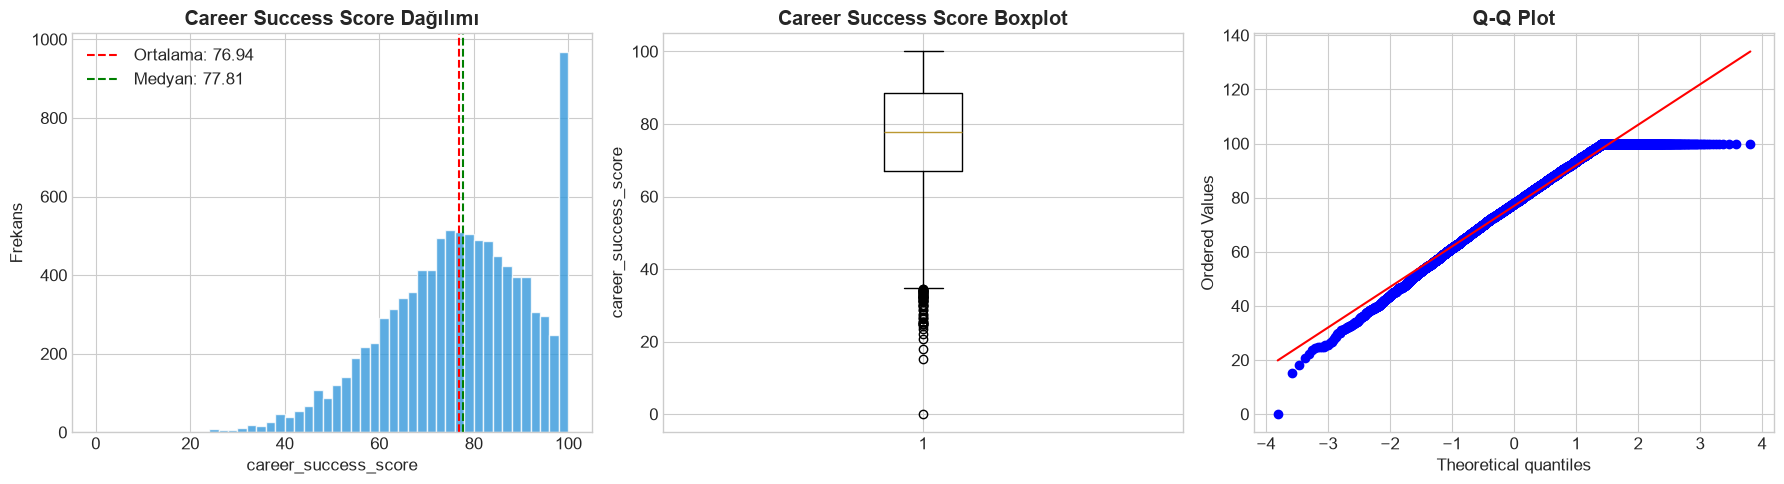

Skewness: -0.4507
Kurtosis: -0.1519


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
axes[0].hist(train['career_success_score'], bins=50, color='#3498db', edgecolor='white', alpha=0.8)
axes[0].axvline(train['career_success_score'].mean(), color='red', linestyle='--', label=f"Ortalama: {train['career_success_score'].mean():.2f}")
axes[0].axvline(train['career_success_score'].median(), color='green', linestyle='--', label=f"Medyan: {train['career_success_score'].median():.2f}")
axes[0].set_title('Career Success Score Dağılımı', fontweight='bold')
axes[0].set_xlabel('career_success_score')
axes[0].set_ylabel('Frekans')
axes[0].legend()

# Boxplot
axes[1].boxplot(train['career_success_score'].dropna(), vert=True)
axes[1].set_title('Career Success Score Boxplot', fontweight='bold')
axes[1].set_ylabel('career_success_score')

# QQ Plot
stats.probplot(train['career_success_score'].dropna(), plot=axes[2])
axes[2].set_title('Q-Q Plot', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Skewness: {train['career_success_score'].skew():.4f}")
print(f"Kurtosis: {train['career_success_score'].kurtosis():.4f}")

### 3.2 Eksik Veri Analizi

In [7]:
# Train ve Test eksik veri
def missing_data_analysis(df, name):
    missing = df.isnull().sum()
    missing_pct = (df.isnull().sum() / len(df)) * 100
    missing_df = pd.DataFrame({'Eksik Sayısı': missing, 'Eksik Yüzde (%)': missing_pct})
    missing_df = missing_df[missing_df['Eksik Sayısı'] > 0].sort_values('Eksik Yüzde (%)', ascending=False)
    print(f'\n=== {name} Eksik Veri ===' )
    if len(missing_df) == 0:
        print('Eksik veri yok!')
    else:
        print(missing_df)
    return missing_df

train_missing = missing_data_analysis(train, 'TRAIN')
test_missing = missing_data_analysis(test, 'TEST')


=== TRAIN Eksik Veri ===
                                Eksik Sayısı  Eksik Yüzde (%)
internship_duration_months              1657            16.57
english_exam_score                       953             9.53
github_avg_stars                         910             9.10
open_source_contribution_count           910             9.10
hr_interview_score                       780             7.80
linkedin_profile_score                   668             6.68
portfolio_score                          364             3.64

=== TEST Eksik Veri ===
                                Eksik Sayısı  Eksik Yüzde (%)
internship_duration_months              1586            15.86
english_exam_score                       944             9.44
github_avg_stars                         895             8.95
open_source_contribution_count           895             8.95
hr_interview_score                       759             7.59
linkedin_profile_score                   680             6.80
portfolio_score    

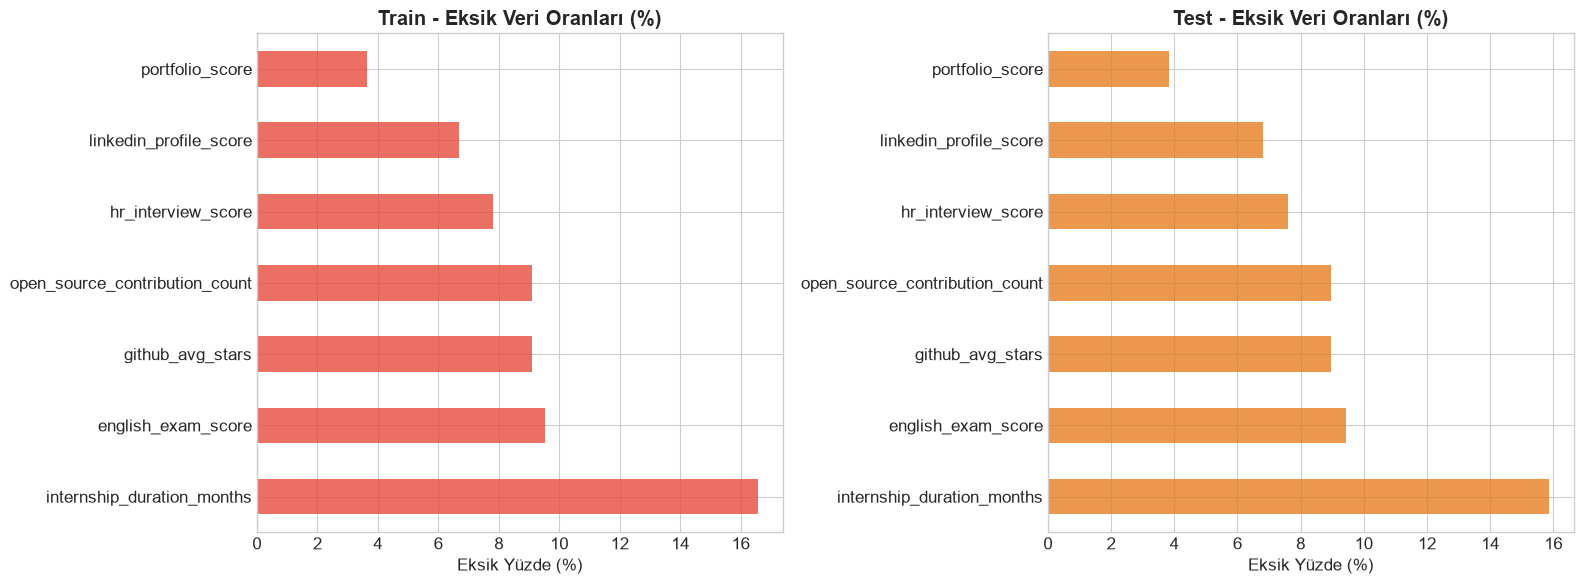

In [8]:
# Eksik veri görselleştirmesi
if len(train_missing) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    train_missing['Eksik Yüzde (%)'].plot(kind='barh', ax=axes[0], color='#e74c3c', alpha=0.8)
    axes[0].set_title('Train - Eksik Veri Oranları (%)', fontweight='bold')
    axes[0].set_xlabel('Eksik Yüzde (%)')
    
    if len(test_missing) > 0:
        test_missing['Eksik Yüzde (%)'].plot(kind='barh', ax=axes[1], color='#e67e22', alpha=0.8)
        axes[1].set_title('Test - Eksik Veri Oranları (%)', fontweight='bold')
        axes[1].set_xlabel('Eksik Yüzde (%)')
    
    plt.tight_layout()
    plt.show()

### 3.3 Kategorik Değişken Analizi

In [9]:
cat_cols = train.select_dtypes(include=['object']).columns.tolist()
if 'student_id' in cat_cols:
    cat_cols.remove('student_id')
if 'mentor_feedback_text' in cat_cols:
    cat_cols.remove('mentor_feedback_text')

print(f'Kategorik kolonlar: {cat_cols}')

for col in cat_cols:
    print(f'\n--- {col} ---')
    print(f'Unique sayısı: {train[col].nunique()}')
    print(train[col].value_counts())

Kategorik kolonlar: ['department', 'university_tier', 'target_role', 'hobby', 'preferred_social_media_platform']

--- department ---
Unique sayısı: 7
department
Computer Engineering                  2961
Software Engineering                  2212
Electrical Electronics Engineering    1850
Industrial Engineering                 806
Statistics                             802
Management Information Systems         769
Mathematics                            600
Name: count, dtype: int64

--- university_tier ---
Unique sayısı: 4
university_tier
Tier 3    3339
Tier 2    3210
Tier 1    1879
Tier 4    1572
Name: count, dtype: int64

--- target_role ---
Unique sayısı: 11
target_role
Backend Developer        1769
Software Developer       1572
Frontend Developer       1312
Data Scientist           1229
Data Analyst             1156
Cloud Engineer            838
AI Engineer               827
DevOps Engineer           525
Cybersecurity Analyst     438
MLOps Engineer            223
Product Analyst  

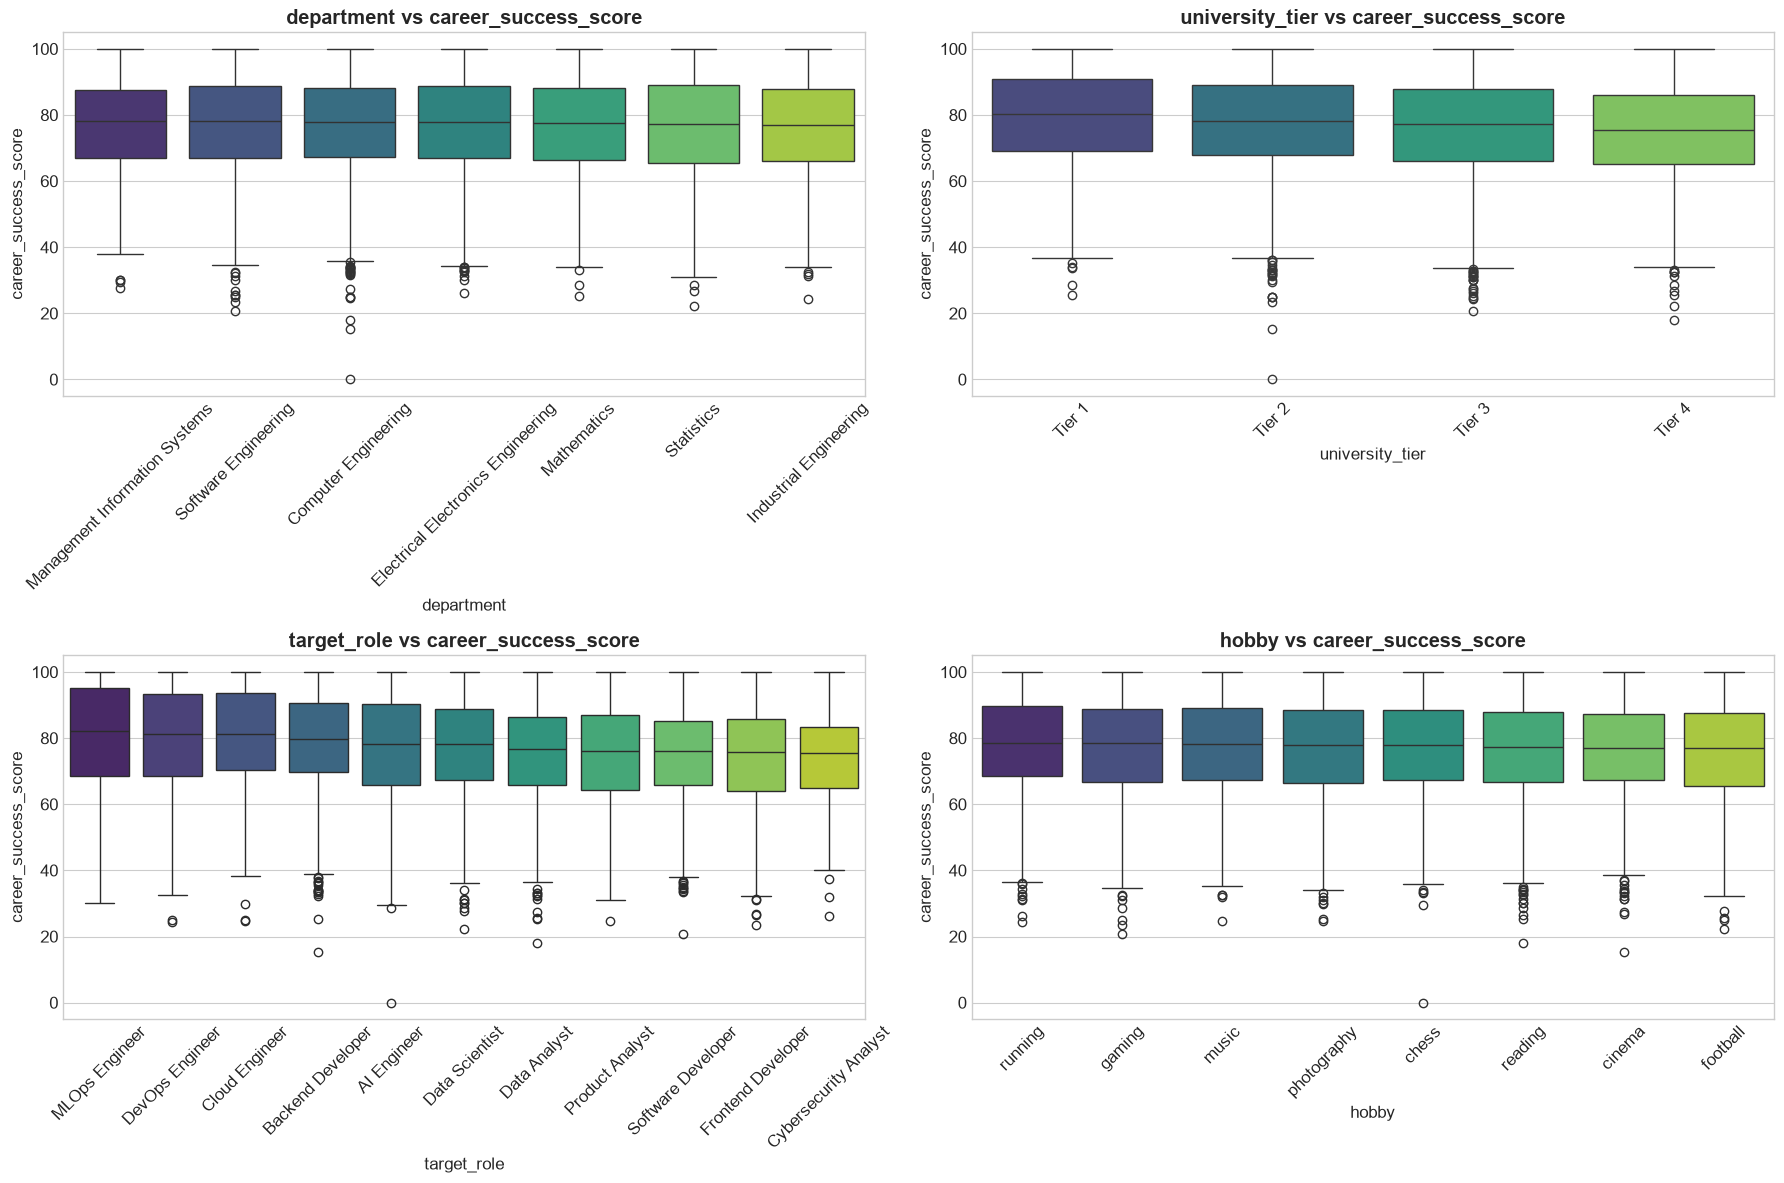

In [10]:
# Kategorik değişkenlere göre hedef değişken dağılımı
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

for i, col in enumerate(cat_cols[:4]):
    ax = axes[i // 2, i % 2]
    order = train.groupby(col)['career_success_score'].median().sort_values(ascending=False).index
    sns.boxplot(data=train, x=col, y='career_success_score', order=order, ax=ax, palette='viridis')
    ax.set_title(f'{col} vs career_success_score', fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### 3.4 Sayısal Değişken Korelasyonu

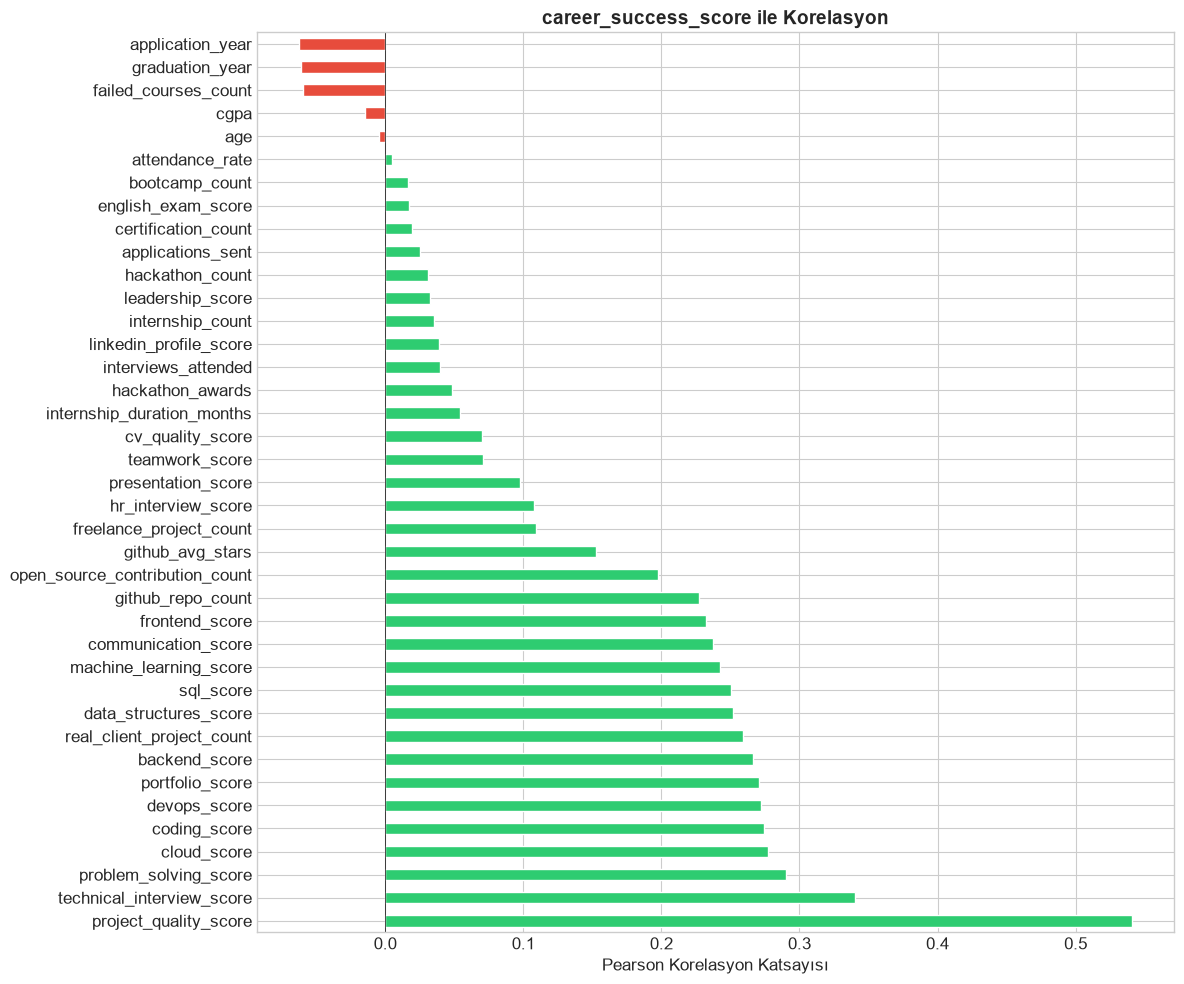

In [11]:
num_cols = train.select_dtypes(include=[np.number]).columns.tolist()
if 'student_id' in num_cols:
    num_cols.remove('student_id')

# Hedef ile korelasyon
correlations = train[num_cols].corr()['career_success_score'].drop('career_success_score').sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 10))
colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in correlations.values]
correlations.plot(kind='barh', ax=ax, color=colors, edgecolor='white')
ax.set_title('career_success_score ile Korelasyon', fontweight='bold', fontsize=14)
ax.set_xlabel('Pearson Korelasyon Katsayısı')
ax.axvline(0, color='black', linewidth=0.5)
plt.tight_layout()
plt.show()

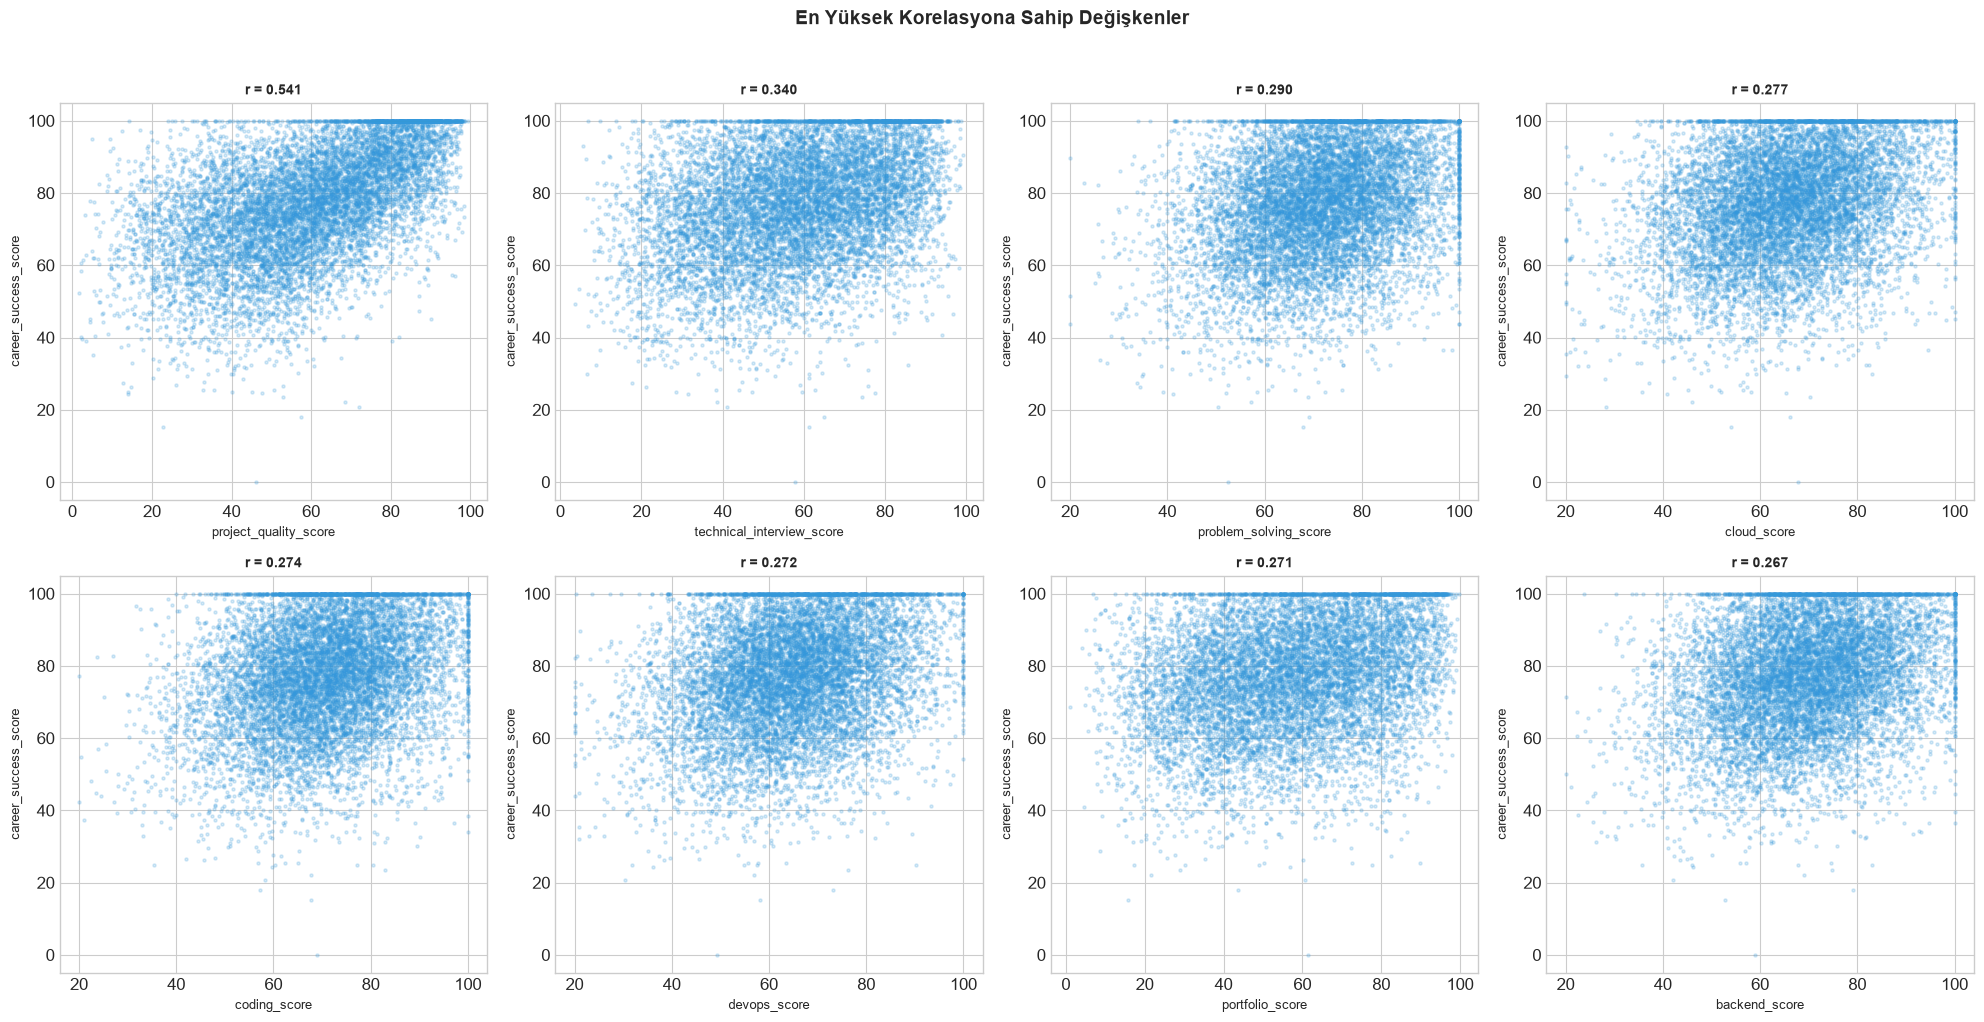

In [12]:
# En yüksek korelasyona sahip değişkenlerin scatter plot'ları
top_corr = correlations.abs().sort_values(ascending=False).head(8).index.tolist()

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
for i, col in enumerate(top_corr):
    ax = axes[i // 4, i % 4]
    ax.scatter(train[col], train['career_success_score'], alpha=0.2, s=5, color='#3498db')
    ax.set_xlabel(col, fontsize=9)
    ax.set_ylabel('career_success_score', fontsize=9)
    ax.set_title(f'r = {correlations[col]:.3f}', fontweight='bold', fontsize=10)

plt.suptitle('En Yüksek Korelasyona Sahip Değişkenler', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 3.5 Korelasyon Isı Haritası (Top Features)

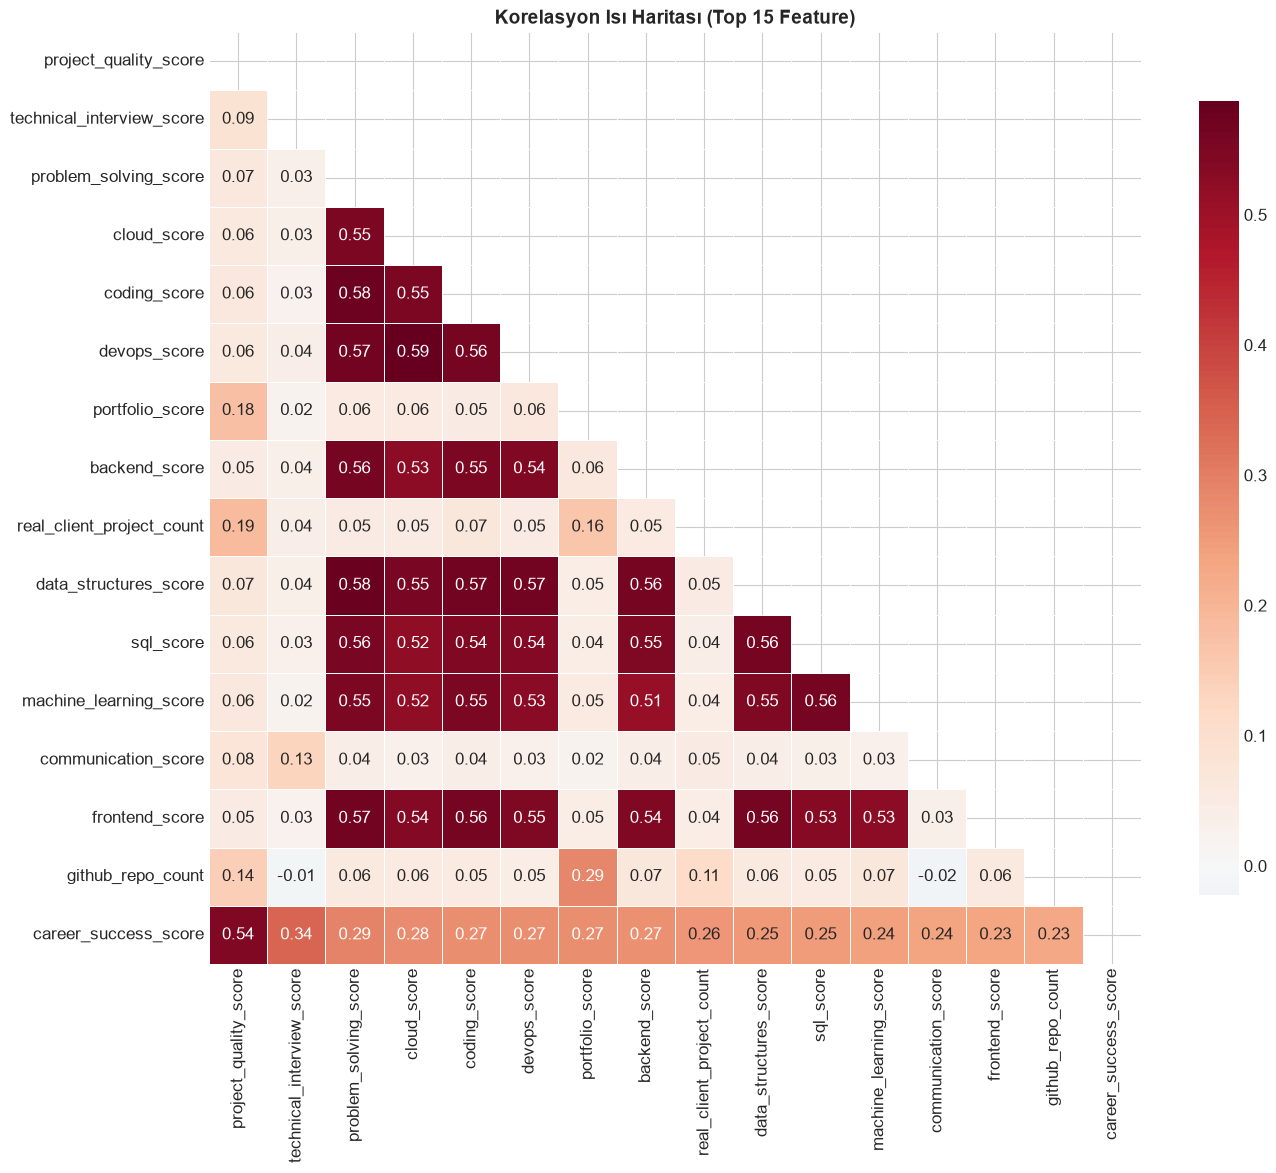

In [13]:
top_features = correlations.abs().sort_values(ascending=False).head(15).index.tolist()
top_features.append('career_success_score')

corr_matrix = train[top_features].corr()

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Korelasyon Isı Haritası (Top 15 Feature)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

## 4. Veri Ön İşleme & Feature Engineering

In [14]:
# Train ve test'i birleştirerek tutarlı ön işleme yapalım
target = train['career_success_score'].copy()
train_ids = train['student_id'].copy()
test_ids = test['student_id'].copy()

# Mentor feedback text'i ayrı tutalım
train_text = train['mentor_feedback_text'].copy()
test_text = test['mentor_feedback_text'].copy()

# Birleştirme
train_len = len(train)
df = pd.concat([train.drop(['career_success_score', 'student_id', 'mentor_feedback_text'], axis=1),
                test.drop(['student_id', 'mentor_feedback_text'], axis=1)], axis=0, ignore_index=True)

print(f'Birleşik dataframe shape: {df.shape}')

Birleşik dataframe shape: (20000, 44)


### 4.1 Eksik Veri Doldurma

In [15]:
# Sayısal eksik verileri medyan ile doldur
num_cols_df = df.select_dtypes(include=[np.number]).columns.tolist()
for col in num_cols_df:
    if df[col].isnull().sum() > 0:
        median_val = df[col].median()
        df[col].fillna(median_val, inplace=True)
        print(f'{col}: Medyan ({median_val:.2f}) ile dolduruldu')

# Kategorik eksik verileri mod ile doldur
cat_cols_df = df.select_dtypes(include=['object']).columns.tolist()
for col in cat_cols_df:
    if df[col].isnull().sum() > 0:
        mode_val = df[col].mode()[0]
        df[col].fillna(mode_val, inplace=True)
        print(f'{col}: Mod ({mode_val}) ile dolduruldu')

print(f'\nToplam eksik veri: {df.isnull().sum().sum()}')

english_exam_score: Medyan (58.03) ile dolduruldu
internship_duration_months: Medyan (7.00) ile dolduruldu
portfolio_score: Medyan (57.90) ile dolduruldu
github_avg_stars: Medyan (2.54) ile dolduruldu
open_source_contribution_count: Medyan (3.00) ile dolduruldu
linkedin_profile_score: Medyan (53.50) ile dolduruldu
hr_interview_score: Medyan (58.38) ile dolduruldu

Toplam eksik veri: 12383


### 4.2 Feature Engineering

In [16]:
# ============================
# 1. Teknik Beceri Agregasyonları
# ============================
tech_skills = ['coding_score', 'problem_solving_score', 'data_structures_score',
               'sql_score', 'machine_learning_score', 'backend_score',
               'frontend_score', 'cloud_score', 'devops_score']

df['tech_skills_mean'] = df[tech_skills].mean(axis=1)
df['tech_skills_std'] = df[tech_skills].std(axis=1)
df['tech_skills_max'] = df[tech_skills].max(axis=1)
df['tech_skills_min'] = df[tech_skills].min(axis=1)
df['tech_skills_range'] = df['tech_skills_max'] - df['tech_skills_min']
df['tech_skills_median'] = df[tech_skills].median(axis=1)

# ============================
# 2. Soft Skills Agregasyonları
# ============================
soft_skills = ['communication_score', 'teamwork_score', 'leadership_score', 'presentation_score']

df['soft_skills_mean'] = df[soft_skills].mean(axis=1)
df['soft_skills_std'] = df[soft_skills].std(axis=1)
df['soft_skills_max'] = df[soft_skills].max(axis=1)
df['soft_skills_min'] = df[soft_skills].min(axis=1)
df['soft_skills_range'] = df['soft_skills_max'] - df['soft_skills_min']

# ============================
# 3. Interview Skorları
# ============================
df['interview_mean'] = df[['technical_interview_score', 'hr_interview_score']].mean(axis=1)
df['interview_diff'] = df['technical_interview_score'] - df['hr_interview_score']

# ============================
# 4. Deneyim Metrikleri
# ============================
df['total_experience'] = (df['real_client_project_count'] + df['internship_count'] +
                          df['freelance_project_count'] + df['hackathon_count'])
df['experience_diversity'] = ((df['real_client_project_count'] > 0).astype(int) +
                               (df['internship_count'] > 0).astype(int) +
                               (df['freelance_project_count'] > 0).astype(int) +
                               (df['hackathon_count'] > 0).astype(int))

# ============================
# 5. Online Varlık
# ============================
df['online_presence'] = df['linkedin_profile_score'] + df['cv_quality_score'] + df['portfolio_score']
df['github_activity'] = df['github_repo_count'] * df['github_avg_stars']

# ============================
# 6. Akademik Performans
# ============================
df['academic_strength'] = df['cgpa'] * df['attendance_rate'] / 100
df['academic_weakness'] = df['failed_courses_count'] / (df['cgpa'] + 0.01)
df['years_since_graduation'] = df['application_year'] - df['graduation_year']

# ============================
# 7. Eğitim Yatırımı
# ============================
df['learning_investment'] = df['certification_count'] + df['bootcamp_count']

# ============================
# 8. İş Arama Verimi
# ============================
df['interview_rate'] = df['interviews_attended'] / (df['applications_sent'] + 1)

# ============================
# 9. Tech vs Soft Skills Dengesi
# ============================
df['tech_soft_ratio'] = df['tech_skills_mean'] / (df['soft_skills_mean'] + 0.01)
df['tech_soft_diff'] = df['tech_skills_mean'] - df['soft_skills_mean']

# ============================
# 10. Overall Score
# ============================
df['overall_score'] = (df['tech_skills_mean'] + df['soft_skills_mean'] + 
                       df['interview_mean'] + df['portfolio_score'] + 
                       df['project_quality_score']) / 5

# ============================
# 11. Interaction Features
# ============================
df['cgpa_x_tech'] = df['cgpa'] * df['tech_skills_mean']
df['project_x_tech'] = df['project_quality_score'] * df['tech_skills_mean']
df['interview_x_soft'] = df['interview_mean'] * df['soft_skills_mean']
df['portfolio_x_github'] = df['portfolio_score'] * df['github_activity']
df['experience_x_tech'] = df['total_experience'] * df['tech_skills_mean']

print(f'Feature Engineering sonrası shape: {df.shape}')
print(f'Eklenen yeni feature sayısı: {df.shape[1] - 43}')

Feature Engineering sonrası shape: (20000, 74)
Eklenen yeni feature sayısı: 31


### 4.3 NLP - Mentor Feedback Text İşleme

In [17]:
# Mentor feedback text'i birleştir
all_text = pd.concat([train_text, test_text], axis=0, ignore_index=True)
all_text = all_text.fillna('')

print(f'Toplam metin sayısı: {len(all_text)}')
print(f'\nÖrnek metin:\n{all_text[0][:200]}...')

Toplam metin sayısı: 20000

Örnek metin:
Proje kalitesi ve makine öğrenimi konusundaki uzmanlığı dikkat çekici. SQL becerisi ile birlikte, DevOps alanında gelişim gösterse de, veri yapıları ve teknik görüşme sonuçlarında daha fazla çalışma y...


In [18]:
# Metin uzunluk feature'ları
df['text_length'] = all_text.str.len()
df['text_word_count'] = all_text.str.split().str.len()
df['text_sentence_count'] = all_text.str.count(r'[.!?]') + 1
df['text_avg_word_length'] = all_text.apply(lambda x: np.mean([len(w) for w in str(x).split()]) if len(str(x).split()) > 0 else 0)

print('Metin uzunluk feature\'ları eklendi.')

Metin uzunluk feature'ları eklendi.


In [19]:
# TF-IDF + SVD ile metin feature extraction
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95,
    sublinear_tf=True
)

tfidf_matrix = tfidf.fit_transform(all_text)
print(f'TF-IDF matrix shape: {tfidf_matrix.shape}')

# SVD ile boyut indirgeme
n_svd_components = 20
svd = TruncatedSVD(n_components=n_svd_components, random_state=SEED)
svd_features = svd.fit_transform(tfidf_matrix)
print(f'SVD açıklanan varyans: {svd.explained_variance_ratio_.sum():.4f}')

# SVD feature'larını dataframe'e ekle
svd_columns = [f'text_svd_{i}' for i in range(n_svd_components)]
svd_df = pd.DataFrame(svd_features, columns=svd_columns)
df = pd.concat([df.reset_index(drop=True), svd_df], axis=1)

print(f'\nNLP sonrası shape: {df.shape}')

TF-IDF matrix shape: (20000, 5000)
SVD açıklanan varyans: 0.0737

NLP sonrası shape: (20000, 98)


### 4.4 Kategorik Değişken Kodlama

In [20]:
cat_cols_encode = df.select_dtypes(include=['object']).columns.tolist()
print(f'Kodlanacak kategorik kolonlar: {cat_cols_encode}')

# Label Encoding
label_encoders = {}
for col in cat_cols_encode:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f'{col}: {len(le.classes_)} sınıf')

print(f'\nKodlama sonrası shape: {df.shape}')
print(f'Toplam null: {df.isnull().sum().sum()}')

Kodlanacak kategorik kolonlar: ['department', 'university_tier', 'target_role', 'hobby', 'preferred_social_media_platform']
department: 7 sınıf
university_tier: 4 sınıf
target_role: 11 sınıf
hobby: 8 sınıf
preferred_social_media_platform: 6 sınıf

Kodlama sonrası shape: (20000, 98)
Toplam null: 20974


### 4.5 Target Encoding (K-Fold ile Leak-Free)

In [21]:
# Kategorik değişkenler için target encoding (sadece train kullanarak)
target_encode_cols = cat_cols_encode.copy()  # Label encode edilmiş hali üzerinden yapacağız

train_df = df.iloc[:train_len].copy()
test_df = df.iloc[train_len:].copy()

kf_te = KFold(n_splits=5, shuffle=True, random_state=SEED)

for col in target_encode_cols:
    train_df[f'{col}_te'] = 0.0
    global_mean = target.mean()
    
    for fold_idx, (tr_idx, val_idx) in enumerate(kf_te.split(train_df)):
        means = train_df.iloc[tr_idx].assign(target=target.iloc[tr_idx]).groupby(col)['target'].mean()
        train_df.iloc[val_idx, train_df.columns.get_loc(f'{col}_te')] = train_df.iloc[val_idx][col].map(means).fillna(global_mean).values
    
    # Test set
    means_full = train_df.assign(target=target.values).groupby(col)['target'].mean()
    test_df[f'{col}_te'] = test_df[col].map(means_full).fillna(global_mean)

# Birleştir
df = pd.concat([train_df, test_df], axis=0, ignore_index=True)
print(f'Target encoding sonrası shape: {df.shape}')

Target encoding sonrası shape: (20000, 103)


## 5. Model Eğitimi

In [22]:
# Train/Test split
X_train = df.iloc[:train_len].copy()
X_test = df.iloc[train_len:].copy()
y_train = target.copy()

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape:  {X_test.shape}')
print(f'y_train shape: {y_train.shape}')

# Feature listesi
features = X_train.columns.tolist()
print(f'\nToplam feature sayısı: {len(features)}')

X_train shape: (10000, 103)
X_test shape:  (10000, 103)
y_train shape: (10000,)

Toplam feature sayısı: 103


### 5.1 K-Fold Cross Validation Framework

In [23]:
N_FOLDS = 10
kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

def train_model_kfold(model_class, params, X, y, X_test, n_folds=N_FOLDS, model_name='Model'):
    """K-Fold CV ile model eğitimi ve OOF prediction hesaplama."""
    oof_preds = np.zeros(len(X))
    test_preds = np.zeros(len(X_test))
    fold_scores = []
    models = []
    
    for fold, (tr_idx, val_idx) in enumerate(kf.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        
        model = model_class(**params)
        
        if model_name == 'CatBoost':
            model.fit(X_tr, y_tr, eval_set=(X_val, y_val), verbose=0)
        elif model_name in ['XGBoost', 'LightGBM']:
            model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=0)
        else:
            model.fit(X_tr, y_tr)
        
        val_pred = model.predict(X_val)
        oof_preds[val_idx] = val_pred
        test_preds += model.predict(X_test) / n_folds
        
        fold_mse = mean_squared_error(y_val, val_pred)
        fold_scores.append(fold_mse)
        models.append(model)
        
        print(f'  Fold {fold+1}/{n_folds} - MSE: {fold_mse:.4f}')
    
    overall_mse = mean_squared_error(y, oof_preds)
    print(f'\n  📊 {model_name} OOF MSE: {overall_mse:.4f} (±{np.std(fold_scores):.4f})')
    
    return oof_preds, test_preds, models, overall_mse

### 5.2 XGBoost

In [24]:
xgb_params = {
    'n_estimators': 3000,
    'max_depth': 7,
    'learning_rate': 0.02,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'min_child_weight': 5,
    'gamma': 0.1,
    'random_state': SEED,
    'n_jobs': -1,
    'early_stopping_rounds': 100,
    'eval_metric': 'rmse',
    'tree_method': 'hist'
}

print('🚀 XGBoost eğitimi başlıyor...')
xgb_oof, xgb_test, xgb_models, xgb_mse = train_model_kfold(
    XGBRegressor, xgb_params, X_train, y_train, X_test, model_name='XGBoost'
)

🚀 XGBoost eğitimi başlıyor...
  Fold 1/10 - MSE: 76.2520
  Fold 2/10 - MSE: 88.5000
  Fold 3/10 - MSE: 82.6542
  Fold 4/10 - MSE: 87.1161
  Fold 5/10 - MSE: 77.5522
  Fold 6/10 - MSE: 74.2461
  Fold 7/10 - MSE: 77.0772
  Fold 8/10 - MSE: 72.7394
  Fold 9/10 - MSE: 85.2723
  Fold 10/10 - MSE: 83.8890

  📊 XGBoost OOF MSE: 80.5299 (±5.3334)


### 5.3 LightGBM

In [25]:
lgb_params = {
    'n_estimators': 3000,
    'max_depth': 7,
    'learning_rate': 0.02,
    'subsample': 0.8,
    'colsample_bytree': 0.7,
    'reg_alpha': 0.1,
    'reg_lambda': 1.0,
    'min_child_samples': 20,
    'num_leaves': 63,
    'random_state': SEED,
    'n_jobs': -1,
    'verbose': -1,
    'callbacks': [lambda env: None] if False else None  # placeholder
}

# callbacks parametresini kaldır, LightGBM'de early stopping fit'te yapılır
del lgb_params['callbacks']

# LightGBM için custom train fonksiyonu
def train_lgbm_kfold(X, y, X_test, n_folds=N_FOLDS):
    oof_preds = np.zeros(len(X))
    test_preds = np.zeros(len(X_test))
    fold_scores = []
    models = []
    
    for fold, (tr_idx, val_idx) in enumerate(kf.split(X, y)):
        X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        
        model = LGBMRegressor(**lgb_params)
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_val, y_val)],
            callbacks=[
                lambda env: None  # suppress output
            ]
        )
        
        val_pred = model.predict(X_val)
        oof_preds[val_idx] = val_pred
        test_preds += model.predict(X_test) / n_folds
        
        fold_mse = mean_squared_error(y_val, val_pred)
        fold_scores.append(fold_mse)
        models.append(model)
        
        print(f'  Fold {fold+1}/{n_folds} - MSE: {fold_mse:.4f}')
    
    overall_mse = mean_squared_error(y, oof_preds)
    print(f'\n  📊 LightGBM OOF MSE: {overall_mse:.4f} (±{np.std(fold_scores):.4f})')
    
    return oof_preds, test_preds, models, overall_mse

print('🚀 LightGBM eğitimi başlıyor...')
lgb_oof, lgb_test, lgb_models, lgb_mse = train_lgbm_kfold(X_train, y_train, X_test)

🚀 LightGBM eğitimi başlıyor...
  Fold 1/10 - MSE: 75.8580
  Fold 2/10 - MSE: 89.2802
  Fold 3/10 - MSE: 82.3689
  Fold 4/10 - MSE: 86.9875
  Fold 5/10 - MSE: 77.6244
  Fold 6/10 - MSE: 73.7391
  Fold 7/10 - MSE: 76.9429
  Fold 8/10 - MSE: 72.7933
  Fold 9/10 - MSE: 86.4920
  Fold 10/10 - MSE: 83.8035

  📊 LightGBM OOF MSE: 80.5890 (±5.6301)


### 5.4 CatBoost

In [26]:
cat_params = {
    'iterations': 3000,
    'depth': 7,
    'learning_rate': 0.03,
    'l2_leaf_reg': 3.0,
    'random_seed': SEED,
    'verbose': 0,
    'early_stopping_rounds': 100,
    'eval_metric': 'RMSE',
    'task_type': 'CPU'
}

print('🚀 CatBoost eğitimi başlıyor...')
cat_oof, cat_test, cat_models, cat_mse = train_model_kfold(
    CatBoostRegressor, cat_params, X_train, y_train, X_test, model_name='CatBoost'
)

🚀 CatBoost eğitimi başlıyor...
  Fold 1/10 - MSE: 75.4707
  Fold 2/10 - MSE: 85.1067
  Fold 3/10 - MSE: 81.2706
  Fold 4/10 - MSE: 85.7310
  Fold 5/10 - MSE: 77.0458
  Fold 6/10 - MSE: 72.5205
  Fold 7/10 - MSE: 76.3578
  Fold 8/10 - MSE: 73.3155
  Fold 9/10 - MSE: 85.0744
  Fold 10/10 - MSE: 82.1983

  📊 CatBoost OOF MSE: 79.4091 (±4.8038)


### 5.5 Model Karşılaştırma


📋 MODEL KARŞILAŞTIRMA
   Model   OOF MSE  OOF RMSE
CatBoost 79.409116  8.911179
 XGBoost 80.529853  8.973843
LightGBM 80.588972  8.977136


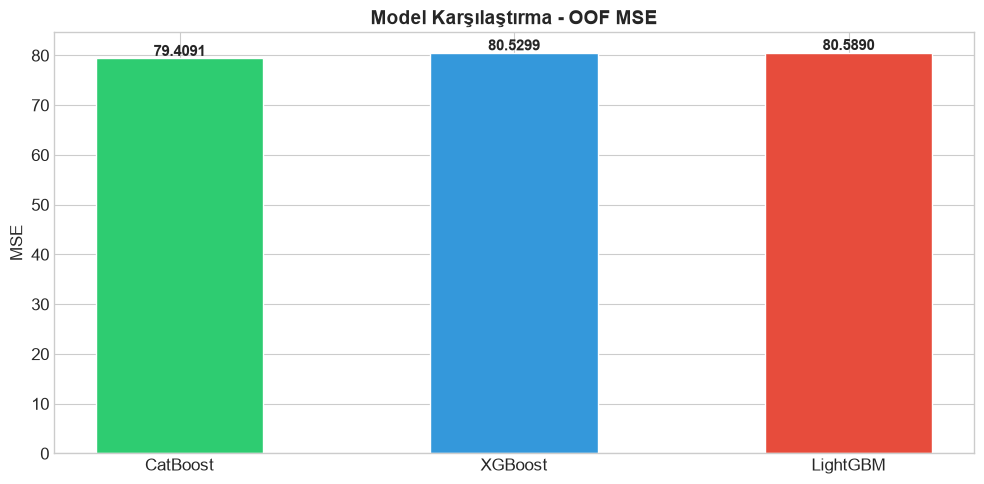

In [27]:
model_results = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM', 'CatBoost'],
    'OOF MSE': [xgb_mse, lgb_mse, cat_mse],
    'OOF RMSE': [np.sqrt(xgb_mse), np.sqrt(lgb_mse), np.sqrt(cat_mse)]
}).sort_values('OOF MSE')

print('\n' + '='*50)
print('📋 MODEL KARŞILAŞTIRMA')
print('='*50)
print(model_results.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71', '#3498db', '#e74c3c']
bars = ax.bar(model_results['Model'], model_results['OOF MSE'], color=colors, edgecolor='white', width=0.5)
ax.set_title('Model Karşılaştırma - OOF MSE', fontweight='bold', fontsize=14)
ax.set_ylabel('MSE')
for bar, val in zip(bars, model_results['OOF MSE']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f'{val:.4f}',
            ha='center', fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

## 6. Feature Importance

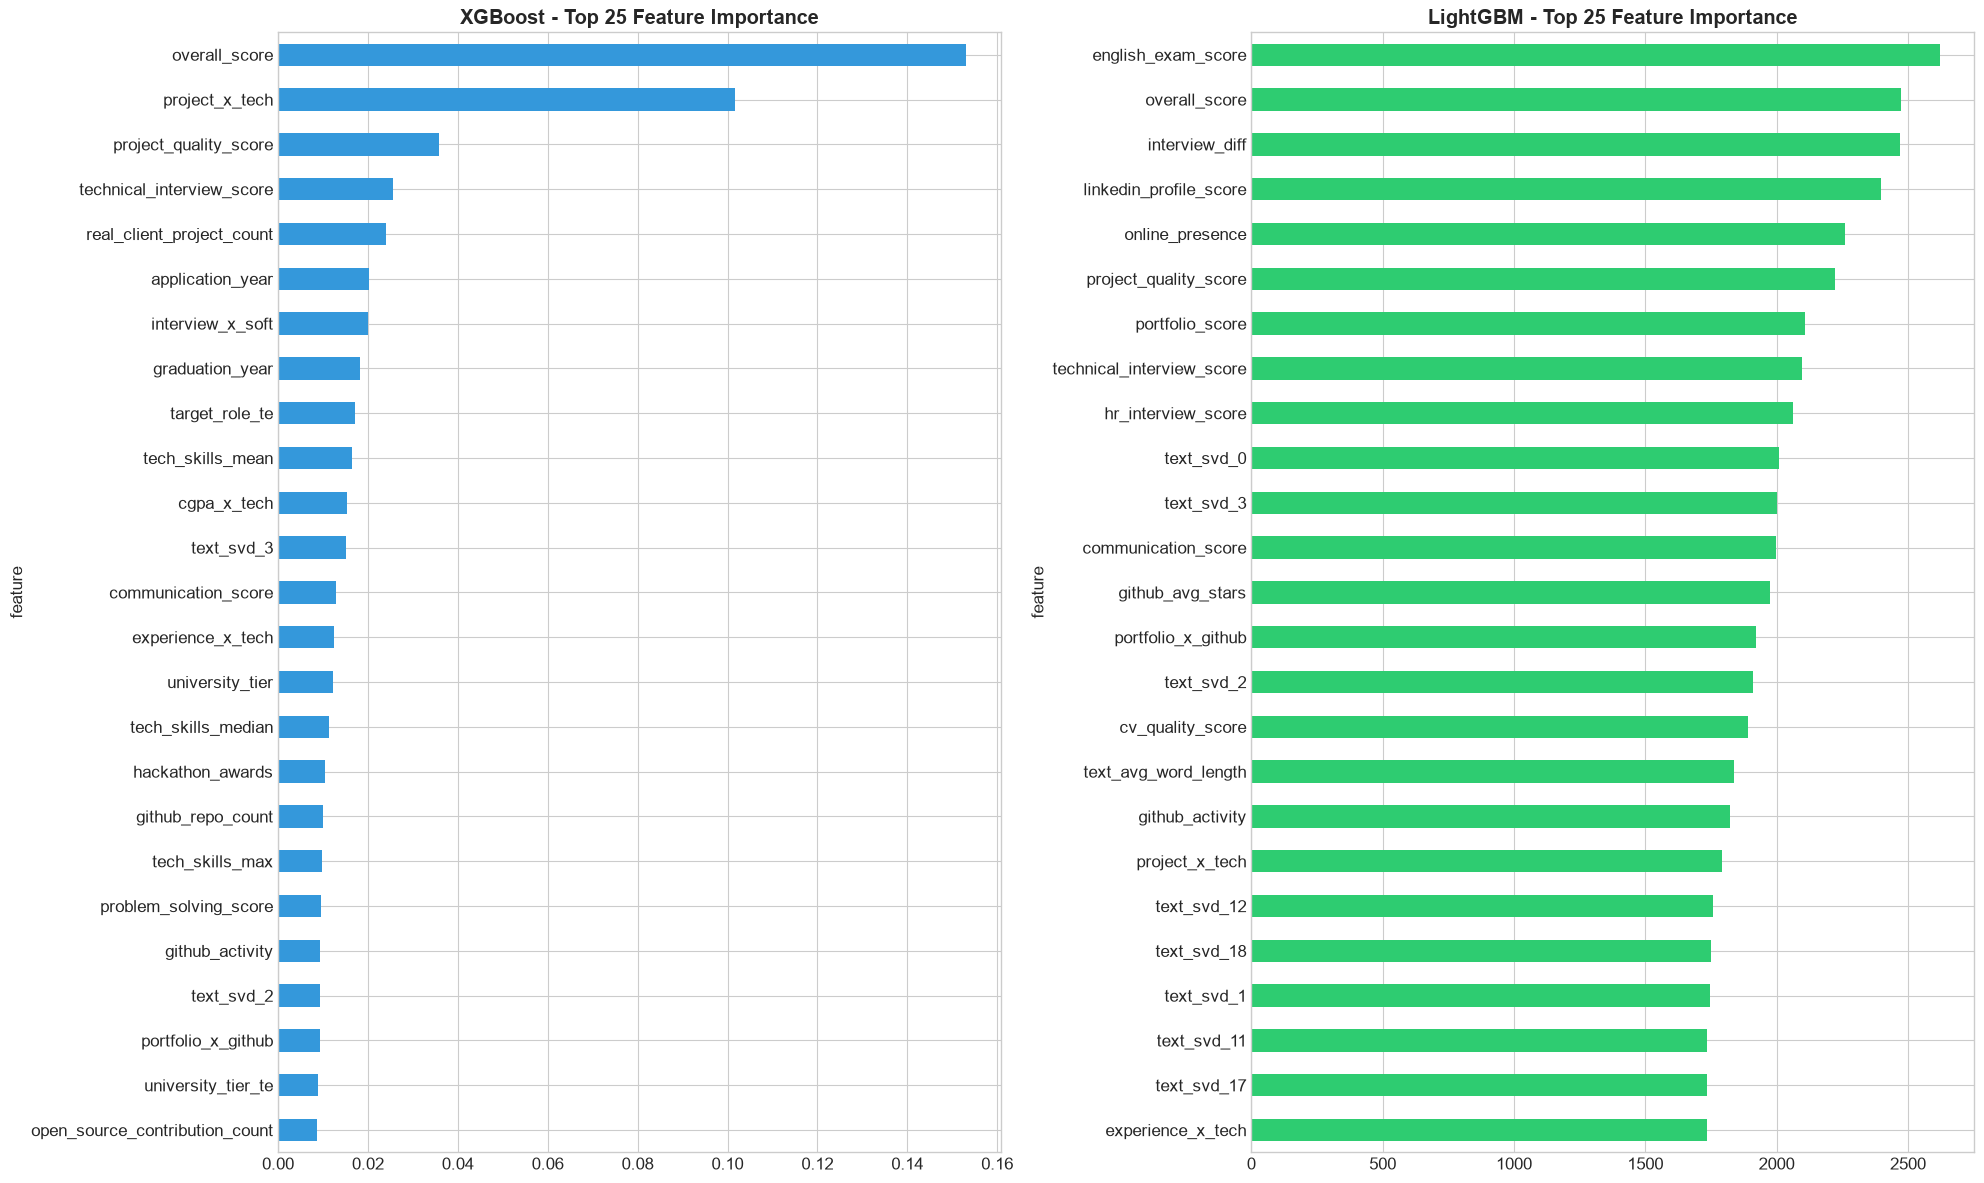

In [28]:
# XGBoost Feature Importance
xgb_imp = pd.DataFrame({
    'feature': features,
    'importance': np.mean([m.feature_importances_ for m in xgb_models], axis=0)
}).sort_values('importance', ascending=False)

# LightGBM Feature Importance
lgb_imp = pd.DataFrame({
    'feature': features,
    'importance': np.mean([m.feature_importances_ for m in lgb_models], axis=0)
}).sort_values('importance', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(20, 12))

xgb_imp.head(25).plot(x='feature', y='importance', kind='barh', ax=axes[0], color='#3498db', legend=False)
axes[0].set_title('XGBoost - Top 25 Feature Importance', fontweight='bold')
axes[0].invert_yaxis()

lgb_imp.head(25).plot(x='feature', y='importance', kind='barh', ax=axes[1], color='#2ecc71', legend=False)
axes[1].set_title('LightGBM - Top 25 Feature Importance', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## 7. Ensemble & Stacking

### 7.1 Weighted Average Ensemble

In [29]:
# Optimal ağırlık arama (grid search)
best_mse = float('inf')
best_weights = None

for w1 in np.arange(0.0, 1.05, 0.05):
    for w2 in np.arange(0.0, 1.05 - w1, 0.05):
        w3 = 1.0 - w1 - w2
        if w3 < 0:
            continue
        
        oof_blend = w1 * xgb_oof + w2 * lgb_oof + w3 * cat_oof
        mse = mean_squared_error(y_train, oof_blend)
        
        if mse < best_mse:
            best_mse = mse
            best_weights = (w1, w2, w3)

print(f'\n✅ En İyi Ağırlıklar: XGB={best_weights[0]:.2f}, LGB={best_weights[1]:.2f}, CAT={best_weights[2]:.2f}')
print(f'📊 Weighted Ensemble OOF MSE: {best_mse:.4f}')

# Weighted ensemble test prediction
ensemble_test = best_weights[0] * xgb_test + best_weights[1] * lgb_test + best_weights[2] * cat_test
ensemble_oof = best_weights[0] * xgb_oof + best_weights[1] * lgb_oof + best_weights[2] * cat_oof


✅ En İyi Ağırlıklar: XGB=0.10, LGB=0.30, CAT=0.60
📊 Weighted Ensemble OOF MSE: 78.6806


### 7.2 Stacking (Ridge Meta-Learner)

In [30]:
# Stacking: OOF predictions kullanarak meta-model eğit
stack_X_train = np.column_stack([xgb_oof, lgb_oof, cat_oof])
stack_X_test = np.column_stack([xgb_test, lgb_test, cat_test])

# Ridge Regression meta-learner
meta_model = Ridge(alpha=1.0)
meta_cv_scores = cross_val_score(meta_model, stack_X_train, y_train,
                                  cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
                                  scoring='neg_mean_squared_error')

print(f'📊 Stacking (Ridge) CV MSE: {-meta_cv_scores.mean():.4f} (±{meta_cv_scores.std():.4f})')

# Tüm train verisi ile eğit
meta_model.fit(stack_X_train, y_train)
stacking_test = meta_model.predict(stack_X_test)
stacking_oof = meta_model.predict(stack_X_train)

stacking_mse = mean_squared_error(y_train, stacking_oof)
print(f'📊 Stacking OOF MSE: {stacking_mse:.4f}')
print(f'\nMeta-model ağırlıkları: {meta_model.coef_}')
print(f'Meta-model intercept: {meta_model.intercept_:.4f}')

📊 Stacking (Ridge) CV MSE: 78.5906 (±4.1696)
📊 Stacking OOF MSE: 78.5479

Meta-model ağırlıkları: [0.14886269 0.3061157  0.57552735]
Meta-model intercept: -2.3368


### 7.3 Final Ensemble Seçimi


📋 FINAL SONUÇLAR
           Yöntem   OOF MSE  OOF RMSE
 Stacking (Ridge) 78.547932  8.862727
Weighted Ensemble 78.680583  8.870208
         CatBoost 79.409116  8.911179
          XGBoost 80.529853  8.973843
         LightGBM 80.588972  8.977136

🏆 En İyi Yöntem: Stacking (Ridge)


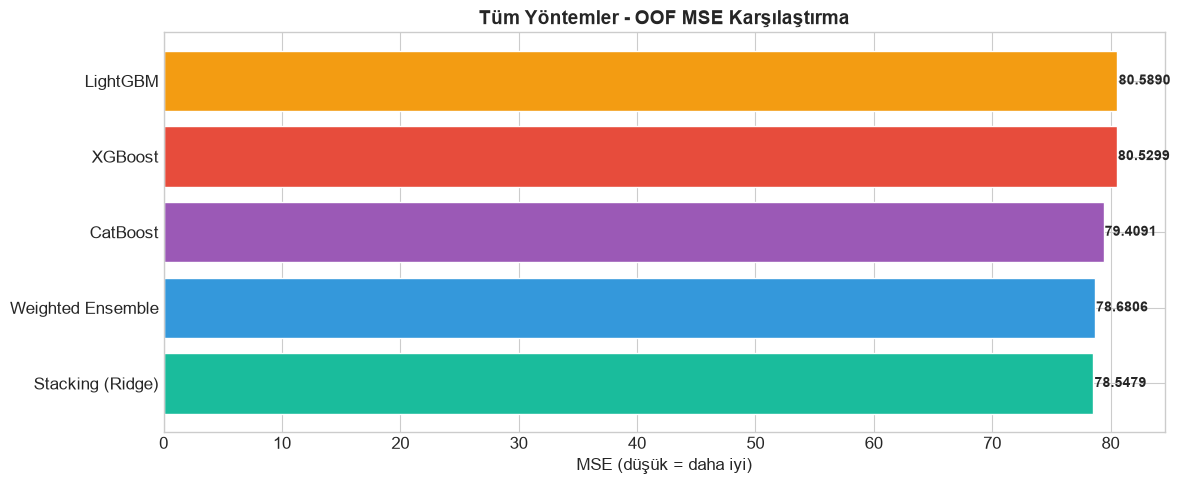

In [31]:
print('\n' + '='*60)
print('📋 FINAL SONUÇLAR')
print('='*60)

all_results = pd.DataFrame({
    'Yöntem': ['XGBoost', 'LightGBM', 'CatBoost', 'Weighted Ensemble', 'Stacking (Ridge)'],
    'OOF MSE': [xgb_mse, lgb_mse, cat_mse, best_mse, stacking_mse],
    'OOF RMSE': [np.sqrt(xgb_mse), np.sqrt(lgb_mse), np.sqrt(cat_mse), np.sqrt(best_mse), np.sqrt(stacking_mse)]
}).sort_values('OOF MSE')

print(all_results.to_string(index=False))

# En iyi yöntem
best_method = all_results.iloc[0]['Yöntem']
print(f'\n🏆 En İyi Yöntem: {best_method}')

# En iyi tahminleri seç
results_map = {
    'XGBoost': xgb_test,
    'LightGBM': lgb_test,
    'CatBoost': cat_test,
    'Weighted Ensemble': ensemble_test,
    'Stacking (Ridge)': stacking_test
}
final_predictions = results_map[best_method]

fig, ax = plt.subplots(figsize=(12, 5))
colors = ['#1abc9c', '#3498db', '#9b59b6', '#e74c3c', '#f39c12']
bars = ax.barh(all_results['Yöntem'], all_results['OOF MSE'], color=colors[:len(all_results)], edgecolor='white')
ax.set_title('Tüm Yöntemler - OOF MSE Karşılaştırma', fontweight='bold', fontsize=14)
ax.set_xlabel('MSE (düşük = daha iyi)')
for bar, val in zip(bars, all_results['OOF MSE']):
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height()/2, f'{val:.4f}',
            va='center', fontweight='bold', fontsize=10)
plt.tight_layout()
plt.show()

## 8. Submission Dosyası Oluşturma

In [32]:
# Submission oluştur
submission = pd.DataFrame({
    'student_id': test_ids,
    'career_success_score': final_predictions
})

# Tahminleri makul aralıkta tut (0-100)
submission['career_success_score'] = submission['career_success_score'].clip(0, 100)

print(f'Submission shape: {submission.shape}')
print(f'\nTahmin istatistikleri:')
print(submission['career_success_score'].describe())

submission.head(10)

Submission shape: (10000, 2)

Tahmin istatistikleri:
count    10000.000000
mean        76.112411
std         12.960413
min         34.015042
25%         66.867077
50%         75.892625
75%         86.109289
max        100.000000
Name: career_success_score, dtype: float64


,student_id,career_success_score
0,STU_010001,59.880381
1,STU_010002,75.005051
2,STU_010003,70.952986
3,STU_010004,96.195969
4,STU_010005,77.903479
5,STU_010006,75.637939
6,STU_010007,77.894757
7,STU_010008,77.113688
8,STU_010009,71.578689
9,STU_010010,56.473538


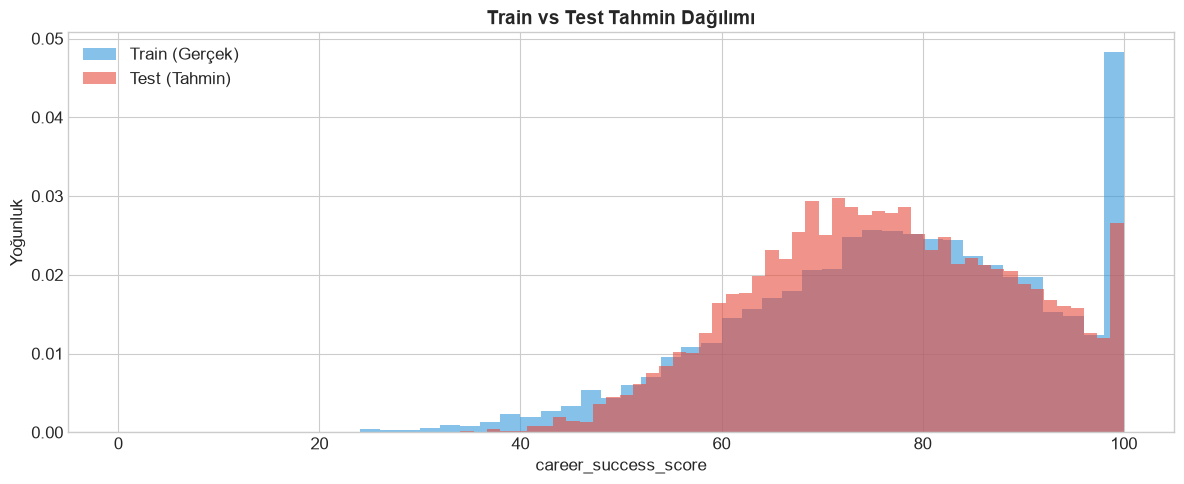

In [33]:
# Tahmin dağılımı vs Train dağılımı
fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(y_train, bins=50, alpha=0.6, color='#3498db', label='Train (Gerçek)', density=True)
ax.hist(submission['career_success_score'], bins=50, alpha=0.6, color='#e74c3c', label='Test (Tahmin)', density=True)
ax.set_title('Train vs Test Tahmin Dağılımı', fontweight='bold', fontsize=14)
ax.set_xlabel('career_success_score')
ax.set_ylabel('Yoğunluk')
ax.legend(fontsize=12)
plt.tight_layout()
plt.show()

In [34]:
# CSV olarak kaydet
submission.to_csv('submission.csv', index=False)
print('✅ submission.csv dosyası oluşturuldu!')

# Kontrol
check = pd.read_csv('submission.csv')
print(f'\nDosya kontrolü:')
print(f'Shape: {check.shape}')
print(f'Kolonlar: {list(check.columns)}')
print(f'\nİlk 5 satır:')
check.head()

✅ submission.csv dosyası oluşturuldu!

Dosya kontrolü:
Shape: (10000, 2)
Kolonlar: ['student_id', 'career_success_score']

İlk 5 satır:


,student_id,career_success_score
0,STU_010001,59.880381
1,STU_010002,75.005051
2,STU_010003,70.952986
3,STU_010004,96.195969
4,STU_010005,77.903479


## 📝 Özet

### Yapılanlar:
1. **EDA**: Hedef değişken analizi, eksik veri, korelasyon, kategorik analiz
2. **Feature Engineering**: 25+ yeni feature (teknik beceri agregasyonları, soft skill metrikleri, deneyim özellikleri, etkileşim terimleri)
3. **NLP**: TF-IDF + SVD ile mentor feedback text'inden feature extraction, metin uzunluk metrikleri
4. **Target Encoding**: K-Fold leak-free target encoding
5. **Modeller**: XGBoost, LightGBM, CatBoost (10-Fold CV)
6. **Ensemble**: Weighted average (grid search optimal ağırlıklar) + Ridge stacking
7. **Submission**: En iyi yöntem ile tahminler oluşturuldu